# Capstone A — FreshMart Retail Chain: Sales Intelligence Pipeline
**Python for Full Stack Data Science with AI & Generative AI · Naresh IT · Lead Trainer: Ajit Byru**

**The client.** Five supermarkets, one owner, a daily total per store and nothing else. Twelve promotions this year; nobody knows if any worked. She wants one tool she can run every month.

**What this notebook does.** It *imports your package* — nothing is cleaned or computed here that isn't a function in `freshmart/`. The notebook is the findings; the package is the product.

**Rules:** no `sklearn`; every cleaning rule is a function that writes to the `QualityLog`; the CLI must run; fresh-kernel run before submission.

---
## Session 1 — Load, validate, clean (through the package)

### 1.1 Load with validation
`SalesLoader` raises `DataFileError` if a file is missing and `SchemaError` if columns are missing. Prove both exceptions work before trusting the loader.

In [1]:
from freshmart import SalesLoader, DataFileError, SchemaError, QualityLog
from freshmart.cleaner import clean_sales, clean_products
from freshmart.report import top_margin, promo_lift, patterns, stockouts, store_productivity
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
loader = SalesLoader("data") 
d = loader.load_all()
print({k: v.shape for k, v in d.items()})

{'sales': (40284, 7), 'products': (120, 6), 'stores': (5, 5), 'promotions': (12, 6)}


In [2]:
# YOUR CODE HERE
# Hint: try: SalesLoader('no_such_folder') except DataFileError; then a folder with a bad sales file -> SchemaError
# 1.1 — Load with validation

from freshmart import SalesLoader, DataFileError, SchemaError

# -------------------------------------------------
# Test 1: Missing folder -> DataFileError
# -------------------------------------------------

try:
    SalesLoader("no_such_folder")
except DataFileError as e:
    print("✓ DataFileError works")
    print("  ", e)


# -------------------------------------------------
# Test 2: Bad schema -> SchemaError
# -------------------------------------------------

from pathlib import Path
import tempfile
import pandas as pd

with tempfile.TemporaryDirectory() as temp_dir:

    # Create a sales file with missing required columns
    bad_sales = pd.DataFrame({
        "receipt_id": [1],
        "store_id": [1]
        # product_id, sale_date, qty, unit_price,
        # discount_pct are intentionally missing
    })

    bad_sales.to_csv(
        Path(temp_dir) / "sales_2025.csv",
        index=False
    )

    # Try loading it
    try:
        SalesLoader(temp_dir)._read("sales_2025.csv")
    except SchemaError as e:
        print("\n✓ SchemaError works")
        print("  ", e)


# -------------------------------------------------
# Test 3: Load the actual FreshMart data
# -------------------------------------------------

loader = SalesLoader("data")
d = loader.load_all()

print("\n===== FILES LOADED SUCCESSFULLY =====")

for name, df in d.items():
    print(f"{name}: {df.shape}")

✓ DataFileError works
   Data folder does not exist: no_such_folder

✓ SchemaError works
   sales_2025.csv is missing required columns: ['product_id', 'sale_date', 'qty', 'unit_price', 'discount_pct']

===== FILES LOADED SUCCESSFULLY =====
sales: (40284, 7)
products: (120, 6)
stores: (5, 5)
promotions: (12, 6)


### 1.2 Profile the raw sales file
Before writing any cleaning rule, look. `info()`, `describe()`, nulls, duplicates, and the *type* of `unit_price`.

In [3]:
# YOUR CODE HERE
# Hint: info(), isna().sum(), duplicated().sum(), look at unit_price and sale_date samples, qty.min(), store_id values
### 1.2 Profile the raw sales file

# 1.2 — Profile the raw sales file

sales = d["sales"]

# 1. Basic information
print("===== INFO =====")
sales.info()

# 2. Statistical summary
print("\n===== DESCRIBE =====")
display(sales.describe(include="all"))

# 3. Missing values
print("\n===== NULL VALUES =====")
display(sales.isna().sum())

# 4. Duplicate rows
print("\n===== DUPLICATES =====")
print("Number of duplicate rows:", sales.duplicated().sum())

# 5. Type of unit_price
print("\n===== UNIT_PRICE TYPE =====")
print("unit_price dtype:", sales["unit_price"].dtype)

# 6. Sample unit_price values
print("\n===== SAMPLE UNIT_PRICE VALUES =====")
display(sales["unit_price"].head(20))

# 7. Sample sale_date values
print("\n===== SAMPLE SALE_DATE VALUES =====")
display(sales["sale_date"].head(20))

# 8. Quantity minimum
print("\n===== QUANTITY CHECK =====")
print("Minimum qty:", sales["qty"].min())

# 9. Store IDs
print("\n===== STORE IDs =====")
print(sorted(sales["store_id"].dropna().unique()))

===== INFO =====
<class 'pandas.DataFrame'>
RangeIndex: 40284 entries, 0 to 40283
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   receipt_id    40284 non-null  str    
 1   store_id      40284 non-null  int64  
 2   product_id    40284 non-null  int64  
 3   sale_date     40284 non-null  str    
 4   qty           40284 non-null  int64  
 5   unit_price    40284 non-null  str    
 6   discount_pct  39984 non-null  float64
dtypes: float64(1), int64(3), str(3)
memory usage: 2.2 MB

===== DESCRIBE =====


,receipt_id,store_id,product_id,sale_date,qty,unit_price,discount_pct
count,40284,40284.000000,40284.000000,40284,40284.000000,40284,39984.000000
unique,40134,NaN,NaN,730,NaN,186,NaN
top,R2512095,NaN,NaN,2025-11-15,NaN,52.0,NaN
freq,2,NaN,NaN,157,NaN,4742,NaN
mean,NaN,3.009855,1068.090532,NaN,2.503028,NaN,0.143933
std,NaN,1.318607,224.901729,NaN,1.677722,NaN,1.593266
min,NaN,1.000000,1001.000000,NaN,-6.000000,NaN,0.000000
25%,NaN,2.000000,1032.000000,NaN,1.000000,NaN,0.000000
50%,NaN,3.000000,1073.000000,NaN,2.000000,NaN,0.000000
75%,NaN,4.000000,1093.000000,NaN,4.000000,NaN,0.000000



===== NULL VALUES =====


receipt_id        0
store_id          0
product_id        0
sale_date         0
qty               0
unit_price        0
discount_pct    300
dtype: int64


===== DUPLICATES =====
Number of duplicate rows: 150

===== UNIT_PRICE TYPE =====
unit_price dtype: str

===== SAMPLE UNIT_PRICE VALUES =====


0      22.0
1     159.0
2     352.0
3      70.0
4      66.0
5     352.0
6      56.0
7      66.0
8      49.0
9      40.0
10     78.0
11     32.0
12    283.0
13      ₹78
14     72.0
15    150.0
16    348.0
17     83.0
18    130.0
19    292.0
Name: unit_price, dtype: str


===== SAMPLE SALE_DATE VALUES =====


0     2025-11-06
1     2025-04-25
2     2025-07-18
3     2025-02-23
4     2025-03-05
5     21/02/2025
6     2025-11-10
7     2025-02-03
8     2025-10-31
9     2025-08-22
10    2025-10-29
11    2025-12-04
12    2025-05-12
13    15/04/2025
14    2025-06-22
15    23/03/2025
16    17/07/2025
17    2025-05-25
18    2025-05-27
19    2025-01-18
Name: sale_date, dtype: str


===== QUANTITY CHECK =====
Minimum qty: -6

===== STORE IDs =====
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


### 1.3 The generator
`stream_sales()` yields the file in chunks. Use it to count rows and sum `qty` **without loading the whole file** — then compare timing and memory with a plain `read_csv`.

In [ ]:
# YOUR CODE HERE
# Hint: for chunk in loader.stream_sales(): rows += len(chunk) ... ; compare with pd.read_csv timing
# 1.3 — The generator
import time
import pandas as pd
# ==========================================================
# 1. Using stream_sales() generator
# ==========================================================
start = time.perf_counter()
row_count = 0
qty_total = 0
for chunk in loader.stream_sales(chunksize=5000):
    row_count += len(chunk)
    qty_total += chunk["qty"].sum()
stream_time = time.perf_counter() - start
print("===== GENERATOR RESULT =====")
print("Rows:", row_count)
print("Total quantity:", qty_total)
print("Time:", round(stream_time, 4), "seconds")
# ==========================================================
# 2. Using normal read_csv()
# ==========================================================
start = time.perf_counter()
sales_full = pd.read_csv("data/sales_2025.csv")
normal_rows = len(sales_full)
normal_qty = sales_full["qty"].sum()
normal_time = time.perf_counter() - start
print("\n===== NORMAL read_csv RESULT =====")
print("Rows:", normal_rows)
print("Total quantity:", normal_qty)
print("Time:", round(normal_time, 4), "seconds")
# ==========================================================
# 3. Compare results
# ==========================================================
print("\n===== COMPARISON =====")
print("Same row count:",
      row_count == normal_rows)
print("Same quantity:",
      qty_total == normal_qty)
print("Generator time:",
      round(stream_time, 4), "seconds")
print("Normal read_csv time:",
      round(normal_time, 4), "seconds")

===== GENERATOR RESULT =====
Rows: 40284
Total quantity: 100832
Time: 0.0968 seconds

===== NORMAL read_csv RESULT =====
Rows: 40284
Total quantity: 100832
Time: 0.0455 seconds

===== COMPARISON =====
Same row count: True
Same quantity: True
Generator time: 0.0968 seconds
Normal read_csv time: 0.0455 seconds


### 1.4 Clean through the package
`clean_products` then `clean_sales`. Everything they did is in the `QualityLog` — print it. This table is graded.

In [ ]:
# 1.4 — Clean through the package
from freshmart.cleaner import QualityLog, clean_products, clean_sales
# Create quality log
log = QualityLog()
# -------------------------------------------------
# Step 1: Clean products
# -------------------------------------------------
products_clean = clean_products(
    d["products"],
    log
)
# -------------------------------------------------
# Step 2: Clean sales
# -------------------------------------------------
sales_clean = clean_sales(
    d["sales"],
    products_clean,
    d["stores"],
    log
)
# -------------------------------------------------
# Step 3: Print quality log
# -------------------------------------------------
print("===== DATA QUALITY LOG =====")
quality_log = log.to_frame()
display(quality_log)
print("\nNumber of cleaning rules logged:", len(quality_log))

===== DATA QUALITY LOG =====


,problem,rows_affected,fix,why
0,Product name has leading/trailing whitespace,3,Strip whitespace from product_name,Keeps product names consistent for reporting a...
1,Product cost price is greater than selling price,1,Flag these products with margin_ok=False,Do not silently change reference prices; exclu...
2,Duplicate sales rows,150,Remove exact duplicate rows,Prevents the same transaction from being count...
3,unit_price contains text/non-numeric values,2408,Convert unit_price to numeric; invalid values ...,Revenue calculations require numeric prices
4,Rows with invalid unit_price,2408,Remove rows with unusable unit_price,A sale cannot produce reliable revenue without...
5,Invalid or inconsistent sale_date formats,0,Parse sale_date using mixed date-format handling,Creates a consistent datetime field for time-b...
6,Rows with invalid sale_date,0,Remove rows with unusable dates,Time-based sales analysis requires valid dates
7,Negative quantity,38,Remove rows with negative qty,Negative sales quantities are invalid for this...
8,Unknown product_id,24,Remove sales rows whose product_id is not in p...,Ensures every sale can be matched to product i...
9,Unknown store_id,10,Remove sales rows whose store_id is not in sto...,Ensures every sale belongs to a known store



Number of cleaning rules logged: 11


**Your Data-Quality Log lives in the package.** Every rule you add to `cleaner.py` must call `log.add(problem, rows, fix, why)`. The stubs are there; the `why` column is graded.

### 1.5 Acceptance
Print the final shape and the sum of `revenue`. These are the numbers you compare with the trainer's.

In [ ]:
# YOUR CODE HERE
# Hint: sales.shape, sales['revenue'].sum(), save sales_clean.csv
### 1.5 Acceptance
print("=====  ACCEPTANCE =====")
print("Final shape:", sales_clean.shape)
print(
    "Total revenue:",
    round(sales_clean["revenue"].sum(), 2)
)

=====  ACCEPTANCE =====
Final shape: (37654, 9)
Total revenue: 10446460.0


---
## Session 2 — Questions 1–3

### Q1. Top products by **margin**, per store
Margin = (net price − cost) × qty. Revenue ranks the expensive; margin ranks the profitable. Do the top-10 lists differ between the biggest store and the smallest?

Biggest store: FreshMart Gachibowli | Store ID: 4 | Area: 7500
Smallest store: FreshMart Dilsukhnagar | Store ID: 5 | Area: 3900
top_margin took 0.0253 seconds
top_margin took 0.0169 seconds

===== TOP 10 — BIGGEST STORE =====


,product_id,product_name,category,units,revenue,margin
0,1046,GROC-14,Grocery,747,218124.0,84889.08
1,1094,BEVE-12,Beverages,3293,171236.0,61546.17
2,1076,SNAC-14,Snacks,1182,78383.3,34554.74
3,1049,GROC-17,Grocery,300,104400.0,34002.00
4,1110,PERS-12,Personal Care,217,83545.0,31964.10
5,1044,GROC-12,Grocery,763,99190.0,30344.51
6,1109,PERS-11,Personal Care,307,108064.0,27485.71
7,1017,DAIR-17,Dairy,1961,217671.0,26336.23
8,1053,GROC-21,Grocery,443,109864.0,21574.10
9,1118,HOUS-08,Household,264,60984.0,20985.36



===== TOP 10 — SMALLEST STORE =====


,product_id,product_name,category,units,revenue,margin
0,1046,GROC-14,Grocery,358,104536.0,40683.12
1,1094,BEVE-12,Beverages,1788,92976.0,33417.72
2,1049,GROC-17,Grocery,147,51156.0,16660.98
3,1076,SNAC-14,Snacks,522,34974.0,15618.24
4,1017,DAIR-17,Dairy,1088,120768.0,14611.84
5,1044,GROC-12,Grocery,360,46800.0,14317.20
6,1110,PERS-12,Personal Care,87,33495.0,12815.10
7,1053,GROC-21,Grocery,259,64232.0,12613.30
8,1109,PERS-11,Personal Care,122,42944.0,10922.66
9,1118,HOUS-08,Household,132,30492.0,10492.68



===== COMPARISON =====
Common products: [1017, 1044, 1046, 1049, 1053, 1076, 1094, 1109, 1110, 1118]
Only in biggest store: []
Only in smallest store: []


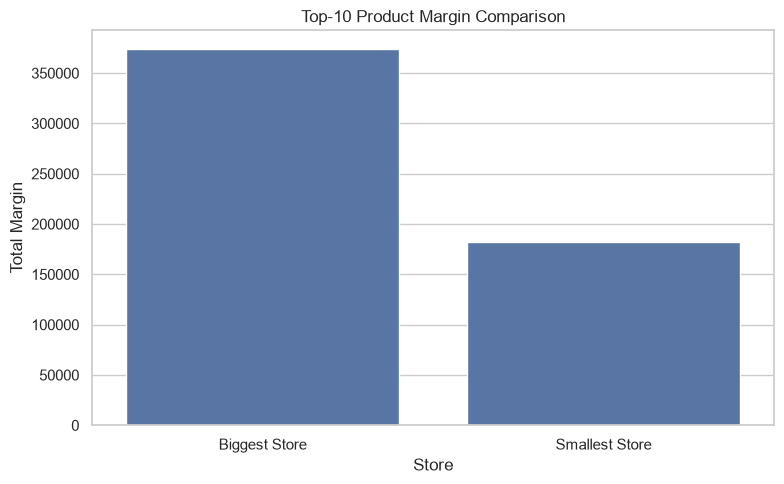

In [ ]:
# YOUR CODE HERE
# Hint: top_margin(sales, products, store_id=4) vs store_id=5; set intersection of names; barplot
# Q1: Top products by margin, per store
# 1. Find biggest and smallest stores
biggest_store = d["stores"].loc[
    d["stores"]["floor_area_sqft"].idxmax()
]
smallest_store = d["stores"].loc[
    d["stores"]["floor_area_sqft"].idxmin()
]
big_id = int(biggest_store["store_id"])
small_id = int(smallest_store["store_id"])
print("Biggest store:", biggest_store["store_name"],
      "| Store ID:", big_id,
      "| Area:", biggest_store["floor_area_sqft"])
print("Smallest store:", smallest_store["store_name"],
      "| Store ID:", small_id,
      "| Area:", smallest_store["floor_area_sqft"])
# Top 10 by margin
top_biggest = top_margin(
    sales_clean,
    products_clean,
    store_id=big_id,
    n=10
)
top_smallest = top_margin(
    sales_clean,
    products_clean,
    store_id=small_id,
    n=10
)
# Display results
print("\n===== TOP 10 — BIGGEST STORE =====")
display(top_biggest)
print("\n===== TOP 10 — SMALLEST STORE =====")
display(top_smallest)
# Compare product lists
big_products = set(top_biggest["product_id"])
small_products = set(top_smallest["product_id"])
print("\n===== COMPARISON =====")
print("Common products:", sorted(big_products & small_products))
print("Only in biggest store:", sorted(big_products - small_products))
print("Only in smallest store:", sorted(small_products - big_products))
comparison = pd.DataFrame({
    "Store": ["Biggest Store", "Smallest Store"],
    "Top_10_Margin": [
        top_biggest["margin"].sum(),
        top_smallest["margin"].sum()
    ]
})
plt.figure(figsize=(8, 5))
sns.barplot(
    data=comparison,
    x="Store",
    y="Top_10_Margin"
)
plt.title("Top-10 Product Margin Comparison")
plt.xlabel("Store")
plt.ylabel("Total Margin")
plt.tight_layout()
plt.show()

*Reading:*

### Q2. Did each promotion lift sales?
For each promotion: daily quantity during the 14 promo days vs the same weekdays in the 8 weeks before. A permutation test gives the p-value. **Reading:** which promotions worked, which didn't, and what do the ones that didn't have in common?

promo_lift took 0.3322 seconds


,promo_id,product_id,store_id,promo_qty_per_day,baseline_qty_per_day,lift_pct,p_value,worked
0,PR01,1077,4,6.857143,4.982143,37.634409,0.151848,False
1,PR02,1053,2,1.571429,1.000000,57.142857,0.465534,False
2,PR03,1076,4,8.785714,2.428571,261.764706,0.000999,True
3,PR04,1073,4,6.428571,2.714286,136.842105,0.008991,True
4,PR05,1032,4,8.857143,2.892857,206.172840,0.000999,True
5,PR06,1032,2,5.857143,2.946429,98.787879,0.003996,True
6,PR07,1113,4,6.500000,1.535714,323.255814,0.000999,True
7,PR08,1113,2,3.071429,1.375000,123.376623,0.017982,True
8,PR09,1073,2,1.857143,2.267857,-18.110236,0.632368,False
9,PR10,1077,2,3.357143,3.142857,6.818182,0.894106,False


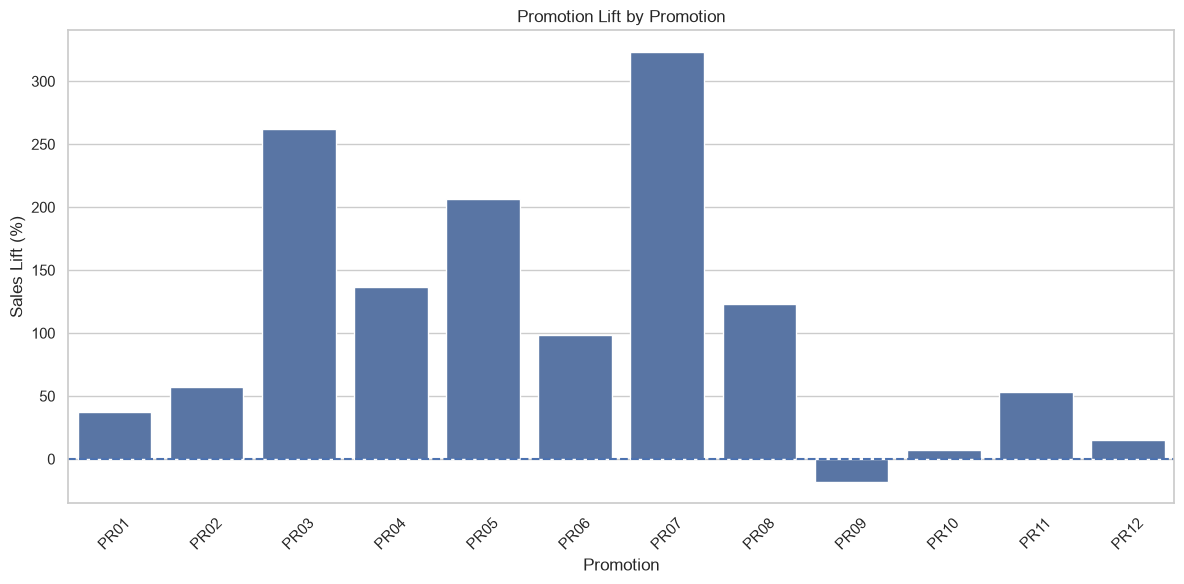

In [ ]:
# YOUR CODE HERE
# Hint: promo_lift(sales, d['promotions']); bar chart coloured by p < 0.05
# Q2: Promotion effectiveness
promo_results = promo_lift(
    sales_clean,
    d["promotions"],
    rng=np.random.default_rng(42),
    n_perm=1000
)

# A promotion "worked" when lift is positive
# and the permutation p-value is below 0.05
promo_results["worked"] = (
    (promo_results["lift_qty_per_day"] > 0)
    & (promo_results["p_value"] < 0.05)
)
# Print the results
display(
    promo_results[
        [
            "promo_id",
            "product_id",
            "store_id",
            "promo_qty_per_day",
            "baseline_qty_per_day",
            "lift_pct",
            "p_value",
            "worked"
        ]
    ]
)
# Plot
plt.figure(figsize=(12, 6))
sns.barplot(
    data=promo_results,
    x="promo_id",
    y="lift_pct"
)
plt.axhline(0, linestyle="--")
plt.title("Promotion Lift by Promotion")
plt.xlabel("Promotion")
plt.ylabel("Sales Lift (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

*Reading:*

### Q3. Weekday and monthly patterns per category
Two heatmaps. **Reading:** where does the weekend peak sit, and does the perishable category (Dairy, Bakery) behave differently?

patterns took 0.0598 seconds


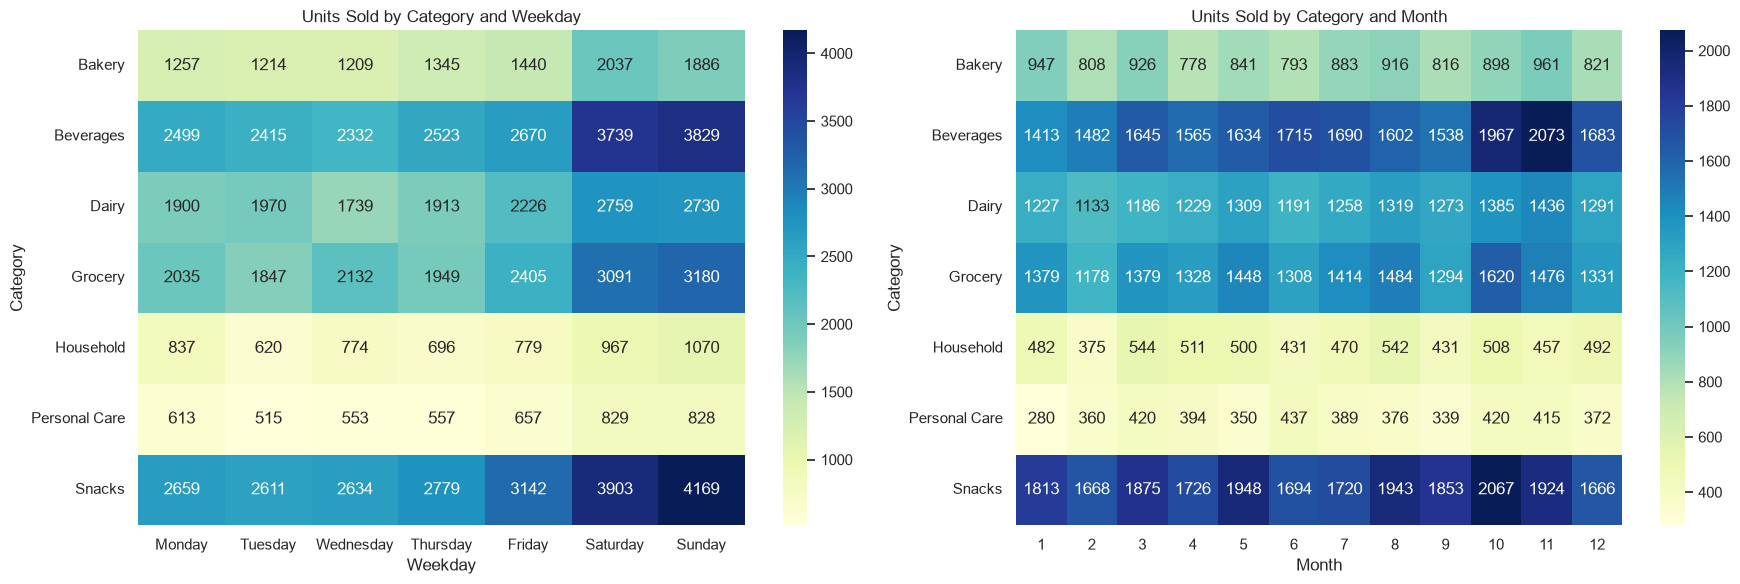

In [ ]:
# YOUR CODE HERE
# Hint: wd, mo = patterns(sales, products); two heatmaps
# Q3 — Weekday and Monthly Patterns per Category

weekday_table, month_table = patterns(
    sales_clean,
    products_clean
)
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
# 1. Weekday heatmap
sns.heatmap(
    weekday_table,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    ax=axes[0]
)
axes[0].set_title("Units Sold by Category and Weekday")
axes[0].set_xlabel("Weekday")
axes[0].set_ylabel("Category")
# 2. Monthly heatmap
sns.heatmap(
    month_table,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    ax=axes[1]
)
axes[1].set_title("Units Sold by Category and Month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Category")
plt.tight_layout()
plt.show()

*Reading:*

---
## Session 3 — Questions 4–6, CLI, recommendation

### Q4. Stock-outs
A product-store pair that normally sells several times a day and then shows zero for 6+ consecutive days. **Reading:** how much revenue did each stock-out cost (average daily revenue × days)?

stockouts took 0.9293 seconds


,product_id,store_id,avg_receipts_per_day,zero_run_days,stockout_start,stockout_end,avg_daily_revenue,estimated_revenue_cost
0,1094,2,2.967123,8,2025-08-17,2025-08-24,127.143121,1017.144968


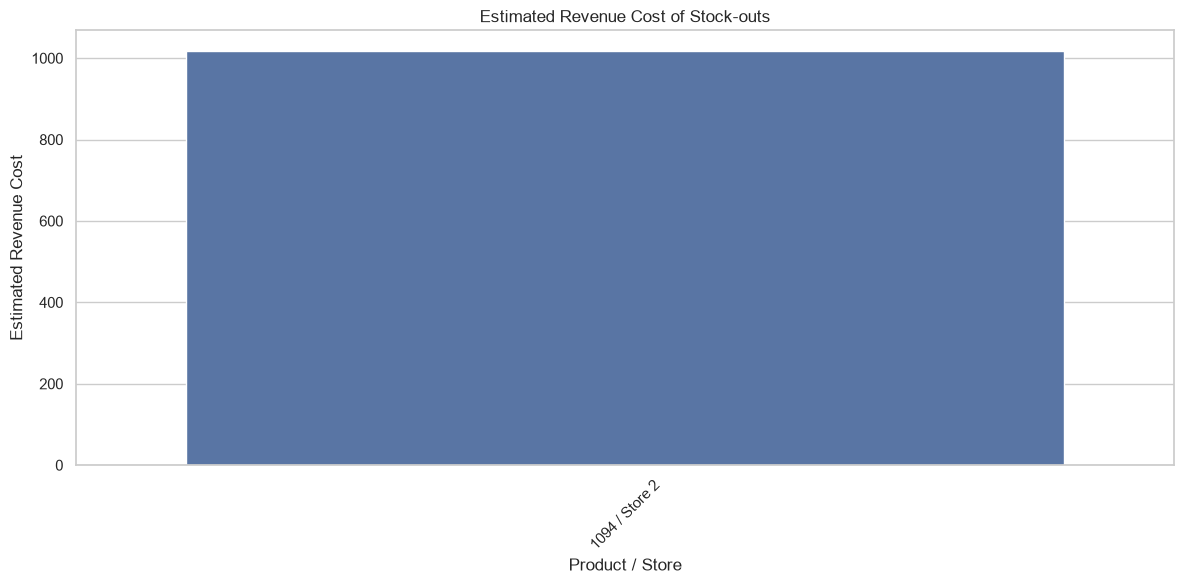

In [ ]:
# YOUR CODE HERE
# Hint: stockouts(sales); revenue lost = avg daily revenue x zero days
# Q4 — Stock-outs
stockout_results = stockouts(
    sales_clean,
    min_rate=1.5,
    min_run=6
)
# Calculate average daily revenue for each product-store pair
avg_revenue = (
    sales_clean
    .groupby(["product_id", "store_id"])["revenue"]
    .mean()
    .reset_index(name="avg_daily_revenue")
)
# Combine
stockout_results = stockout_results.merge(
    avg_revenue,
    on=["product_id", "store_id"],
    how="left"
)
# Estimated revenue cost
stockout_results["estimated_revenue_cost"] = (
    stockout_results["avg_daily_revenue"]
    * stockout_results["zero_run_days"]
)
# Display
display(
    stockout_results[
        [
            "product_id",
            "store_id",
            "avg_receipts_per_day",
            "zero_run_days",
            "stockout_start",
            "stockout_end",
            "avg_daily_revenue",
            "estimated_revenue_cost"
        ]
    ].sort_values(
        "estimated_revenue_cost",
        ascending=False
    )
)
# Chart
plt.figure(figsize=(12, 6))
plot_data = stockout_results.copy()
plot_data["product_store"] = (
    plot_data["product_id"].astype(str)
    + " / Store "
    + plot_data["store_id"].astype(str)
)
sns.barplot(
    data=plot_data.sort_values(
        "estimated_revenue_cost",
        ascending=False
    ),
    x="product_store",
    y="estimated_revenue_cost"
)
plt.title("Estimated Revenue Cost of Stock-outs")
plt.xlabel("Product / Store")
plt.ylabel("Estimated Revenue Cost")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

*Reading:*

### Q5. Most profitable store per square foot
Floor area is the owner's scarcest resource. Rank by margin per sq ft, not revenue.

store_productivity took 0.0301 seconds


,store_id,store_name,city,floor_area_sqft,revenue,margin,receipts,margin_per_sqft
0,1,FreshMart Banjara Hills,Hyderabad,4200,1717477.0,473107.75,6080,112.644702
1,4,FreshMart Gachibowli,Hyderabad,7500,2855218.1,781544.59,10422,104.205945
2,3,FreshMart Secunderabad,Secunderabad,5100,1917148.0,527985.93,6822,103.526653
3,5,FreshMart Dilsukhnagar,Hyderabad,3900,1465164.0,402747.08,5466,103.268482
4,2,FreshMart Kukatpally,Hyderabad,6800,2491452.9,679512.90,8864,99.928368


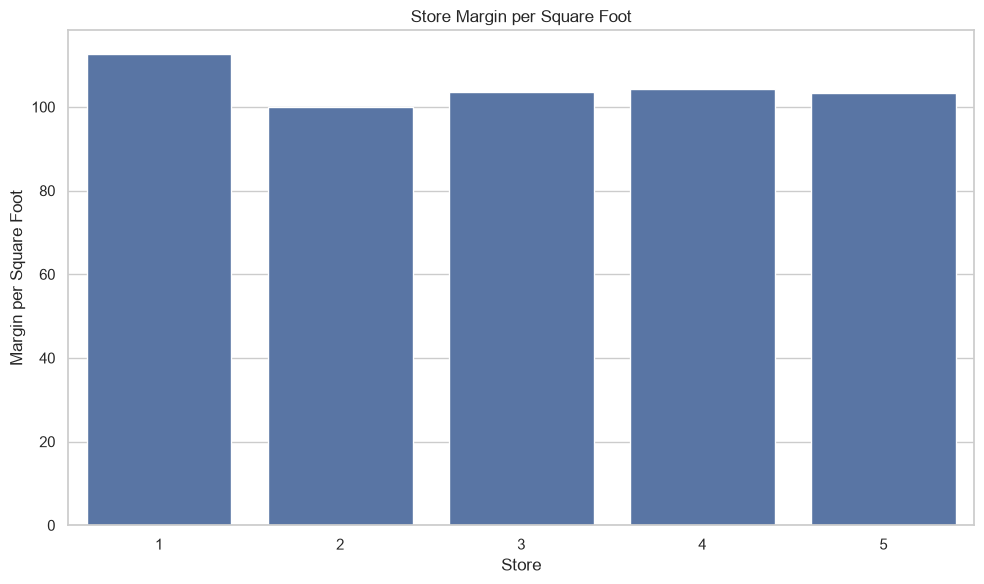

Highest margin per sq ft: Store 1 with 112.64


In [ ]:
# YOUR CODE HERE
# Hint: store_productivity(sales, products, d['stores'])
# Q5 — Most profitable store per square foot
store_results = store_productivity(
    sales_clean,
    products_clean,
    d["stores"]
)
# Display all stores ranked by margin per square foot
store_results = store_results.sort_values(
    "margin_per_sqft",
    ascending=False
).reset_index(drop=True)
display(store_results)
# Chart
plt.figure(figsize=(10, 6))
sns.barplot(
    data=store_results,
    x="store_id",
    y="margin_per_sqft"
)
plt.title("Store Margin per Square Foot")
plt.xlabel("Store")
plt.ylabel("Margin per Square Foot")
plt.tight_layout()
plt.show()
# Print the top store
top_store = store_results.iloc[0]
print(
    f"Highest margin per sq ft: "
    f"Store {top_store['store_id']} "
    f"with {top_store['margin_per_sqft']:.2f}"
)

*Reading:*

### Q6. Your own question
Pick one: discount depth vs lift (do 25% promos beat 10%?) · category mix per store · the Oct–Nov festival effect · returns (the negative-qty rows) by product · receipts per day trend.

promo_lift took 0.3201 seconds
Discount depth vs average sales lift:


,discount_pct,avg_lift_pct,promotions
0,10,110.791574,6
1,15,19.516310,2
2,20,323.255814,1
3,25,91.829888,3


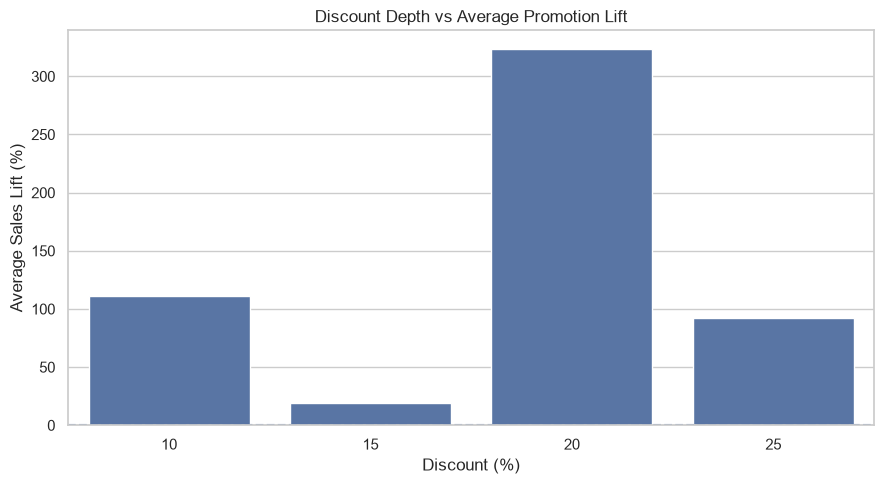

In [ ]:
# YOUR CODE HERE
# Hint: your question, your code
# Q6 — Discount depth vs promotion lift
# Get promotion results from Q2
promo_results = promo_lift(
    sales_clean,
    d["promotions"],
    rng=np.random.default_rng(42),
    n_perm=1000
)
# Add discount percentage
q6 = promo_results.merge(
    d["promotions"][["promo_id", "discount_pct"]],
    on="promo_id",
    how="left"
)
# Compare average lift by discount level
discount_summary = (
    q6.groupby("discount_pct")
      .agg(
          avg_lift_pct=("lift_pct", "mean"),
          promotions=("promo_id", "count")
      )
      .reset_index()
      .sort_values("discount_pct")
)
print("Discount depth vs average sales lift:")
display(discount_summary)
# Plot
plt.figure(figsize=(9, 5))
sns.barplot(
    data=discount_summary,
    x="discount_pct",
    y="avg_lift_pct"
)
plt.axhline(0, linestyle="--")
plt.title("Discount Depth vs Average Promotion Lift")
plt.xlabel("Discount (%)")
plt.ylabel("Average Sales Lift (%)")
plt.tight_layout()
plt.show()

### The CLI
Run it from a terminal in the folder that contains `freshmart/` and `data/`:

```
python -m freshmart report --store 4
python -m freshmart report --store 2 --month 6
```
Paste the output of the first command in the cell below as a comment.

In [15]:
# python -m freshmart report --store 4
# (paste output here)
!python -m freshmart report --store 4
#!python -m freshmart report --store 2 --month 6


TOP MARGIN PRODUCTS
top_margin took 0.0223 seconds
 product_id product_name      category  units  revenue   margin
       1046      GROC-14       Grocery    747 218124.0 84889.08
       1094      BEVE-12     Beverages   3293 171236.0 61546.17
       1076      SNAC-14        Snacks   1182  78383.3 34554.74
       1049      GROC-17       Grocery    300 104400.0 34002.00
       1110      PERS-12 Personal Care    217  83545.0 31964.10
       1044      GROC-12       Grocery    763  99190.0 30344.51
       1109      PERS-11 Personal Care    307 108064.0 27485.71
       1017      DAIR-17         Dairy   1961 217671.0 26336.23
       1053      GROC-21       Grocery    443 109864.0 21574.10
       1118      HOUS-08     Household    264  60984.0 20985.36

STORE PRODUCTIVITY
store_productivity took 0.0215 seconds
 store_id           store_name      city  floor_area_sqft   revenue    margin  receipts  margin_per_sqft
        4 FreshMart Gachibowli Hyderabad             7500 2855218.1 781544.59   

### Recommendation (120–180 words, to the owner)
Finding → number → action for 2026 → one thing you'd check with more data.

> *Your paragraph here.*

### Cliffhanger
Q3 shows every category has a weekly rhythm and a festival peak. The owner asks: "So what will GROC-14 sell in January?" — Module 19.